# Quando a IA aprende o atalho?

**Ensaio computacional em Python** · Ciência da Computação

Um classificador pode acertar quase tudo e ainda assim aprender a regra errada. Neste ensaio, construímos um mundo sintético com dois sinais: um **sinal estável**, que permanece associado ao rótulo em todos os ambientes, e um **atalho**, que é muito preditivo no treino, mas pode inverter no teste. Vamos observar o que o modelo aprende e se diversidade de ambientes ajuda.

> **Pergunta:** quando o desempenho alto indica aprendizado útil — e quando indica apenas que o modelo explorou uma regularidade temporária?

As células são parte do argumento: rode-as em ordem. O conjunto de dados é gerado aqui, sem download, e a semente aleatória torna a experiência reproduzível.

## 1. Um mundo simples para uma pergunta difícil

Imagine um sistema que prevê se uma imagem contém um animal. O formato do animal é um sinal útil; um fundo verde pode funcionar como atalho se quase todas as imagens positivas do treino tiverem grama. Se o fundo mudar, a regra aprendida pode falhar.

Não usaremos imagens: dois números tornam o mecanismo visível. Para cada exemplo, o rótulo `y` é −1 ou +1. O sinal `estavel` aponta para `y` em todos os ambientes. O sinal `atalho` aponta para `y` no ambiente de treino, mas sua associação é controlada por `ambiente`: +1 representa a correlação familiar; −1, a correlação invertida. Ruído impede que qualquer sinal revele o rótulo perfeitamente.

Isso é uma **demonstração controlada**, não uma estimativa sobre sistemas de IA reais. A vantagem é que sabemos exatamente qual relação mudou.

Em termos matemáticos, geramos
$X_{estável} = 1{,}25y + \varepsilon_1$ e
$X_{atalho} = 2ay + \varepsilon_2$, com ruídos normais padrão independentes.
O parâmetro $a$ controla o sentido e a intensidade da associação espúria; ele não é
a correlação de Pearson nem serve como entrada do modelo. Os rótulos são
equiprováveis, mas uma amostra finita não precisa ter exatamente 50% de cada classe.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from experimento import MODELOS, SEMENTE, ajustar_modelos, gerar_dados, resumir, simular

plt.style.use("seaborn-v0_8-whitegrid")
CORES = dict(zip(MODELOS, ("#c24d32", "#067d82", "#49566d"), strict=True))
N_TREINO, N_TESTE = 2_000, 2_000

def escala_acuracia(ax):
    ax.set_ylim(0, 1.03)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel("Acurácia média")
    ax.axhline(0.5, color="#888", linestyle=":", label="Referência de acaso (50%)")

## 2. Um primeiro ajuste: investigar o atalho

A regressão logística procura uma combinação das características que separe
os rótulos. Vamos observar os pesos aprendidos em um único ambiente. Como as
variáveis têm magnitudes diferentes, os coeficientes brutos não são uma
medida universal de importância; a evidência principal virá do teste sob inversão.

In [2]:
ajuste = ajustar_modelos(N_TREINO, np.random.default_rng(SEMENTE))
pesos = {
    nome: pd.Series(modelo.coef_[0], index=[("Estável", "Atalho")[i] for i in MODELOS[nome]])
    for nome, modelo in ajuste.items()
}
display(pd.DataFrame(pesos).round(3).fillna("Não usado"))

,Treino familiar,Treino diversificado,Só sinal estável
Atalho,3.431,-0.010,Não usado
Estável,1.797,2.494,2.53


## 3. Comparação controlada: mesma quantidade, ambientes diferentes

**Hipótese:** o treino familiar se sai bem quando o atalho continua válido, mas perde
desempenho quando ele se inverte; treinar com ambientes opostos reduz essa dependência.

- **Familiar:** 2.000 exemplos de +1, com as duas características.
- **Diversificado:** 1.000 exemplos de +1 (os mesmos da primeira metade do treino
  familiar) e 1.000 de −1, com as duas características.
- **Só sinal estável:** mesmos exemplos do treino familiar, mas sem a coluna do atalho.
  É uma referência diagnóstica: na prática, pode não ser possível identificar esse sinal.

Em cada uma das 80 repetições, os modelos são reajustados em novas amostras.
Cada ambiente de teste tem 2.000 exemplos novos, compartilhados pelos três
modelos. O intervalo de confiança (IC) aproximado de 95% é a média entre
repetições ± 1,96 erros-padrão. Ele quantifica a precisão da média na simulação;
não é um intervalo de previsão para uma execução isolada ou para dados reais.
O teste em −1 é feito em exemplos não vistos, mas o ambiente −1 já é
representado no treino diversificado.

,Modelo,Teste,Média (%),IC inferior (%),IC superior (%)
0,Só sinal estável,Invertido (−1),89.51,89.36,89.67
1,Só sinal estável,Familiar (+1),89.28,89.12,89.44
2,Treino diversificado,Invertido (−1),89.47,89.29,89.65
3,Treino diversificado,Familiar (+1),89.32,89.13,89.50
4,Treino familiar,Invertido (−1),14.87,14.29,15.45
5,Treino familiar,Familiar (+1),99.02,98.97,99.07


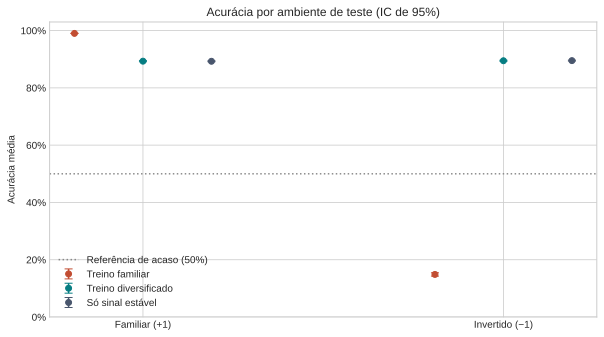

In [3]:
resultados = simular([1, -1], n_treino=N_TREINO, n_teste=N_TESTE)
resumo = resumir(resultados, ["modelo", "ambiente"])
rotulos = {1: "Familiar (+1)", -1: "Invertido (−1)"}

def tabela_percentual(dados):
    return (dados.assign(ambiente=dados["ambiente"].map(rotulos))
            .rename(columns={"modelo": "Modelo", "ambiente": "Teste", "media": "Média (%)",
                             "ic_inf": "IC inferior (%)", "ic_sup": "IC superior (%)"})
            .assign(**{rotulo: (100 * dados[coluna]).round(2)
                       for coluna, rotulo in [("media", "Média (%)"),
                                             ("ic_inf", "IC inferior (%)"),
                                             ("ic_sup", "IC superior (%)")]})
            [["Modelo", "Teste", "Média (%)", "IC inferior (%)", "IC superior (%)"]])

display(tabela_percentual(resumo))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for deslocamento, (nome, cor) in zip((-0.19, 0, 0.19), CORES.items(), strict=True):
    grupo = resumo[resumo["modelo"] == nome].set_index("ambiente").loc[[1, -1]]
    ax.errorbar(np.arange(2) + deslocamento, grupo["media"], yerr=grupo["margem"],
                fmt="o", capsize=4, color=cor, label=nome)
ax.set_xticks([0, 1], [rotulos[1], rotulos[-1]])
escala_acuracia(ax)
ax.set_title("Acurácia por ambiente de teste (IC de 95%)")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

### Qual foi o ganho no teste invertido?

Como os modelos recebem os mesmos exemplos de teste em cada repetição,
calculamos primeiro a diferença entre eles dentro de cada rodada e só depois
tiramos a média. O IC abaixo é calculado diretamente sobre essas diferenças.

In [4]:
pares = resultados.pivot(index=["repeticao", "ambiente"], columns="modelo", values="acuracia")
pares["ganho_pp"] = 100 * (pares["Treino diversificado"] - pares["Treino familiar"])
ganho = resumir(pares.reset_index(), ["ambiente"], coluna="ganho_pp")
display(ganho.assign(ambiente=ganho["ambiente"].map(rotulos))
        [["ambiente", "media", "ic_inf", "ic_sup"]].round(2)
        .rename(columns={"ambiente": "Teste", "media": "Ganho (p.p.)",
                         "ic_inf": "IC inferior (p.p.)", "ic_sup": "IC superior (p.p.)"}))

,Teste,Ganho (p.p.),IC inferior (p.p.),IC superior (p.p.)
0,Invertido (−1),74.6,74.01,75.20
1,Familiar (+1),-9.7,-9.89,-9.52


## 4. E se a mudança for gradual?

Agora variamos o parâmetro do atalho no teste de −1 a +1. Em cada uma das 40
repetições, os mesmos modelos ajustados são usados ao longo da curva. Em zero,
o atalho é apenas ruído: o modelo familiar ainda pode usá-lo porque foi ajustado
em +1. As faixas mostram ICs pontuais da média, não uma faixa simultânea para
toda a curva.

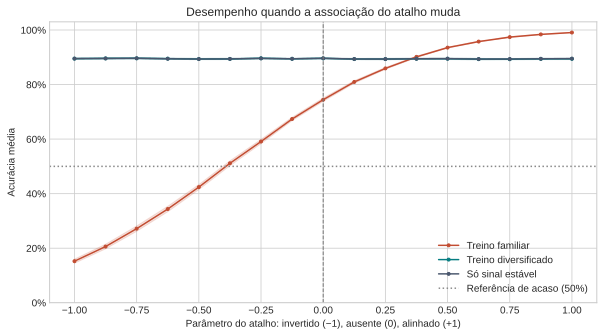

In [5]:
curva = simular(np.linspace(-1, 1, 17), repeticoes=40, n_treino=N_TREINO,
                n_teste=N_TESTE, semente=1900)
curva_resumo = resumir(curva, ["modelo", "ambiente"])

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for nome, cor in CORES.items():
    grupo = curva_resumo[curva_resumo["modelo"] == nome].sort_values("ambiente")
    x = grupo["ambiente"].to_numpy()
    ax.plot(x, grupo["media"].to_numpy(), marker="o", ms=3, color=cor, label=nome)
    ax.fill_between(x, grupo["ic_inf"].to_numpy(), grupo["ic_sup"].to_numpy(),
                    color=cor, alpha=0.16)
ax.axvline(0, color="#777", linestyle="--", linewidth=1)
escala_acuracia(ax)
ax.set_xlabel("Parâmetro do atalho: invertido (−1), ausente (0), alinhado (+1)")
ax.set_title("Desempenho quando a associação do atalho muda")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 5. Conclusão: a pergunta certa depende do teste

O resultado no ambiente familiar mede se o modelo prevê bem sob condições
parecidas com as do treino. Ele não mostra, sozinho, se a regra continua útil
quando essas condições mudam. O treino diversificado sacrifica parte do
desempenho familiar e melhora o resultado após a inversão. A proximidade com a
referência que usa só o sinal estável é compatível com uma dependência menor
do atalho neste cenário.

**Limites.** São dados sintéticos, duas características e um único tipo de
classificador. A intervenção foi favorecida pelo desenho: o sinal estável
continua útil e os atalhos do treino diversificado têm sentidos opostos.
Se todos os ambientes compartilharem o mesmo viés, ou se o sinal estável mudar,
o resultado não é garantido. A acurácia agregada também não descreve custos de
erro ou diferenças por subgrupo.

### Referências e reprodutibilidade


- Wolfram, S. (2017). [What Is a Computational Essay?](https://writings.stephenwolfram.com/2017/11/what-is-a-computational-essay/) — a computação como parte da narrativa, do raciocínio e da descoberta.
- Wolfram Language. [Steps to Writing a Computational Essay](https://www.wolframcloud.com/obj/Expositions/Published/ComputationalEssayGuidelines) — orientações para organizar e desenvolver um ensaio computacional.
- Dados, simulações e figuras deste ensaio são gerados pelo próprio notebook. Semente principal: `2026`; repetições dos experimentos usam sementes próprias fixas para permitir reprodução.